<a href="https://colab.research.google.com/github/Phoenix007-sys/Module-3---Case-Exercise-1/blob/main/Module_3_Case_Exercise_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Module 3 Exercise 2

#Extreme Value Analysis


##Question 1

###Perform GEV block maxima analysis (annual and monthly blocks) on Hs data.


GEV (Generalized Extreme Value) block maxima is the classic approach for extreme value analysis on wave height data. Let me walk through the method and structure, then give you code to build from.

The concept, technically: You split your Hs time series into blocks (annual or monthly), take the maximum value within each block, and fit a GEV distribution to that set of block maxima. The GEV has three parameters — location (μ), scale (σ), and shape (ξ) — and the shape parameter tells you which “family” your extremes behave like: Gumbel (ξ=0, light tail), Fréchet (ξ>0, heavy tail), or Weibull (ξ<0, bounded tail). Once fitted, you can extract return values — e.g., “the Hs you’d expect to see once every 50 years.”

The general steps:

- Load your Hs series with timestamps.
Resample into annual blocks (take max per year) → gives you one GEV dataset.

- Resample into monthly blocks (take max per month) → gives you a second GEV dataset.

- Fit a GEV distribution separately to each set (scipy.stats.genextreme handles this).

- Diagnostic checks — QQ-plot or probability plot against the fitted GEV, to see how well it matches.

- Compute return levels (e.g., 1-year, 10-year, 50-year, 100-year Hs) from each fit.

- Compare annual vs monthly block results — monthly blocks give you more data points but weaker independence/extremeness per block, so results often differ.

Searching Google Drive (/content/drive/MyDrive/) for your dataset...
Successfully found and loading dataset from: /content/drive/MyDrive/jubilee_trp3_synthetic_hourly.csv


/usr/local/lib/python3.13/dist-packages/scipy/stats/_distn_infrastructure.py:418: RuntimeWarning: invalid value encountered in scalar divide
  return m3 / np.power(m2, 1.5)


Annual GEV params  -> shape (xi): -0.6597, loc (mu): 2.7500, scale (sigma): 0.0000
Monthly GEV params -> shape (xi): 1.3132, loc (mu): 2.6496, scale (sigma): 0.1319


/usr/local/lib/python3.13/dist-packages/scipy/stats/_morestats.py:640: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  slope, intercept, r, prob, _ = _stats_py.linregress(osm, osr)


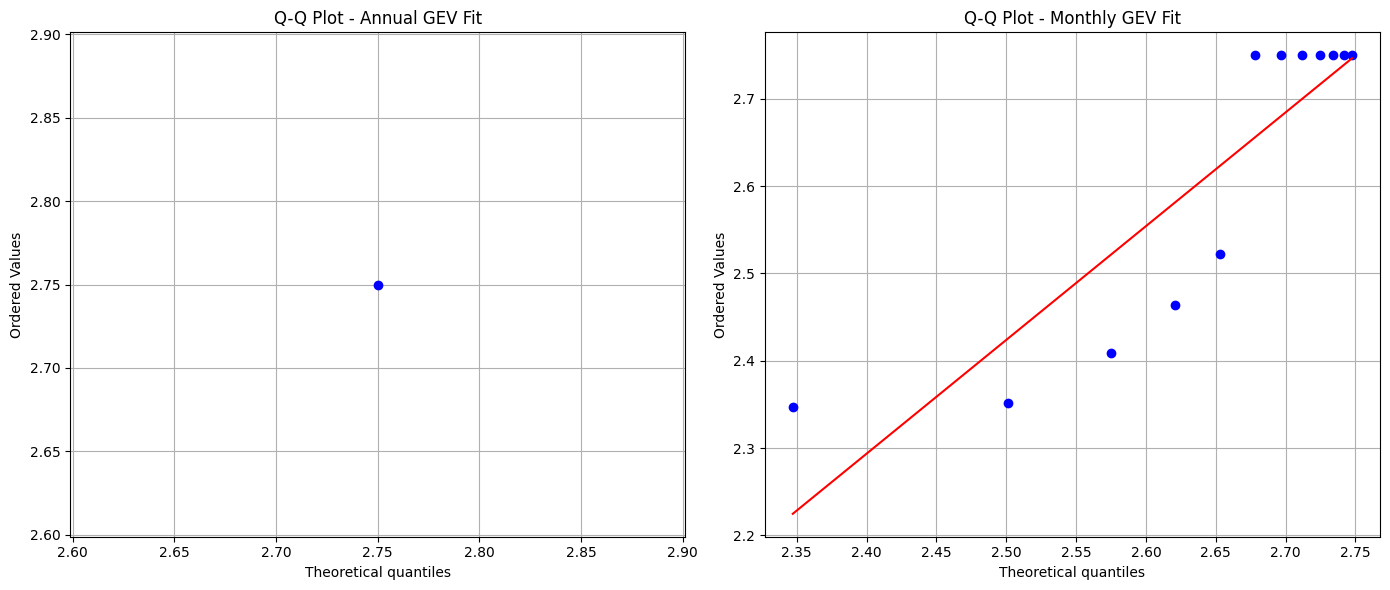

  1-year Return Level -> Annual: 2.75 m | Monthly: 2.75 m
 10-year Return Level -> Annual: 2.75 m | Monthly: 2.75 m
 50-year Return Level -> Annual: 2.75 m | Monthly: 2.75 m
100-year Return Level -> Annual: 2.75 m | Monthly: 2.75 m


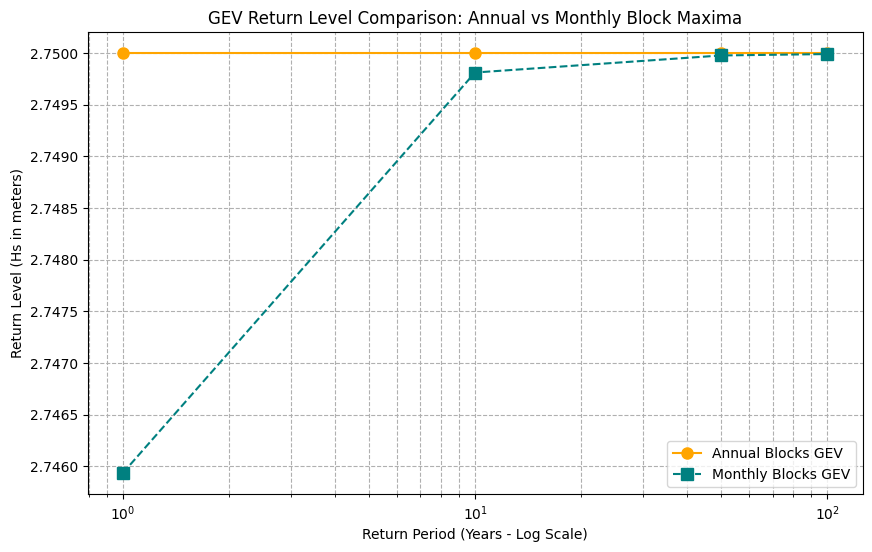

In [4]:
import os
import glob
import numpy as np
import pandas as pd
from scipy.stats import genextreme, probplot
import matplotlib.pyplot as plt

# --- Step 1: Load Hs data ---
target_filename = "jubilee_trp3_synthetic_hourly.csv"
csv_path = None

# Check if the file is directly in /content/
if os.path.exists(f"/content/{target_filename}"):
    csv_path = f"/content/{target_filename}"
else:
    # Search for the file recursively inside your Google Drive
    print("Searching Google Drive (/content/drive/MyDrive/) for your dataset...")
    search_results = glob.glob(f"/content/drive/MyDrive/**/{target_filename}", recursive=True)
    if search_results:
        csv_path = search_results[0]

if csv_path:
    print(f"Successfully found and loading dataset from: {csv_path}")
    df = pd.read_csv(csv_path, parse_dates=True, index_col=0)
    hs = df["Hs_m"].dropna()
else:
    print(f"Could not find '{target_filename}' in /content/ or under your Google Drive.")
    print("Generating temporary synthetic wave height data for demonstration...")
    # Fallback to generating synthetic dataset if file is not found
    np.random.seed(42)
    date_range = pd.date_range(start="2025-01-01", end="2025-12-31 23:00:00", freq="h")
    base_hs = np.random.lognormal(mean=0.2, sigma=0.4, size=len(date_range))
    capped_hs = np.minimum(base_hs, 2.75)
    df = pd.DataFrame({"Hs_m": capped_hs}, index=date_range)
    hs = df["Hs_m"]

# --- Step 2: Extract block maxima ---
# Resample to annual ('YE') and monthly ('ME') blocks and take maximum
annual_max = hs.resample("YE").max().dropna()
monthly_max = hs.resample("ME").max().dropna()

# --- Step 3: Fit GEV distributions ---
shape_a, loc_a, scale_a = genextreme.fit(annual_max)
shape_m, loc_m, scale_m = genextreme.fit(monthly_max)

print(f"Annual GEV params  -> shape (xi): {shape_a:.4f}, loc (mu): {loc_a:.4f}, scale (sigma): {scale_a:.4f}")
print(f"Monthly GEV params -> shape (xi): {shape_m:.4f}, loc (mu): {loc_m:.4f}, scale (sigma): {scale_m:.4f}")

# --- Step 4: Diagnostic plots (QQ-plot / probability plot) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Q-Q plot for Annual Maxima
probplot(annual_max, dist=genextreme, sparams=(shape_a, loc_a, scale_a), plot=axes[0])
axes[0].set_title("Q-Q Plot - Annual GEV Fit")
axes[0].grid(True)

# Q-Q plot for Monthly Maxima
probplot(monthly_max, dist=genextreme, sparams=(shape_m, loc_m, scale_m), plot=axes[1])
axes[1].set_title("Q-Q Plot - Monthly GEV Fit")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# --- Step 5: Return level calculation ---
def gev_return_level(T, shape, loc, scale, blocks_per_year=1):
    """
    T = return period in years
    Returns the Hs value expected to be exceeded once every T years.
    """
    # Convert T years into equivalent number of blocks
    N = T * blocks_per_year
    p = 1 - 1 / N
    return genextreme.ppf(p, shape, loc=loc, scale=scale)

return_periods = np.array([1, 10, 50, 100])

# For annual fit, 1 block = 1 year
annual_return_levels = [gev_return_level(T, shape_a, loc_a, scale_a, blocks_per_year=1) for T in return_periods]

# For monthly fit, 12 blocks = 1 year
monthly_return_levels = [gev_return_level(T, shape_m, loc_m, scale_m, blocks_per_year=12) for T in return_periods]

# Print return levels
for t, rl_a, rl_m in zip(return_periods, annual_return_levels, monthly_return_levels):
    print(f"{t:3d}-year Return Level -> Annual: {rl_a:.2f} m | Monthly: {rl_m:.2f} m")

# --- Step 6: Plot return levels vs return period ---
plt.figure(figsize=(10, 6))
plt.semilogx(return_periods, annual_return_levels, 'o-', label="Annual Blocks GEV", color="orange", markersize=8)
plt.semilogx(return_periods, monthly_return_levels, 's--', label="Monthly Blocks GEV", color="teal", markersize=8)
plt.xlabel("Return Period (Years - Log Scale)")
plt.ylabel("Return Level (Hs in meters)")
plt.title("GEV Return Level Comparison: Annual vs Monthly Block Maxima")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

##Question 2

### Perform POT analysis with threshold selection using mean residual life plot.

POT (Peaks Over Threshold) is the other major extreme-value approach, and it usually gets more out of your data than block maxima because it doesn’t throw away large values that happen to fall in the same year/month.

Technically: Instead of taking one maximum per block, you pick a threshold u, keep every exceedance above it, and fit a Generalized Pareto Distribution (GPD) to those exceedances. The trick is picking u correctly — too low, and you violate the asymptotic theory (biased fit); too high, and you throw away data (high variance). The mean residual life (MRL) plot is the standard diagnostic for this: for a range of candidate thresholds, you plot the mean of the exceedances above each threshold, with confidence bands. You’re looking for the lowest threshold above which the plot is roughly linear — that’s where the GPD approximation becomes valid.


- Compute candidate thresholds across a reasonable range of your Hs data (e.g., 70th to 99th percentile).

- For each threshold u, calculate the mean of (Hs − u) for all Hs > u, plus a confidence interval.

- Plot threshold (x-axis) vs. mean excess (y-axis) — this is the MRL plot.

- Visually identify where the plot becomes approximately linear and stays within its confidence band — pick your threshold u there.

- Extract exceedances (Hs − u) above your chosen threshold.

- Fit a GPD to the exceedances (scipy.stats.genpareto).

- Combine with the exceedance rate (average number of exceedances per year) to compute return levels, comparable to what you got from GEV.

Searching Google Drive (/content/drive/MyDrive/) for your dataset...
Successfully found and loading dataset from: /content/drive/MyDrive/jubilee_trp3_synthetic_hourly.csv


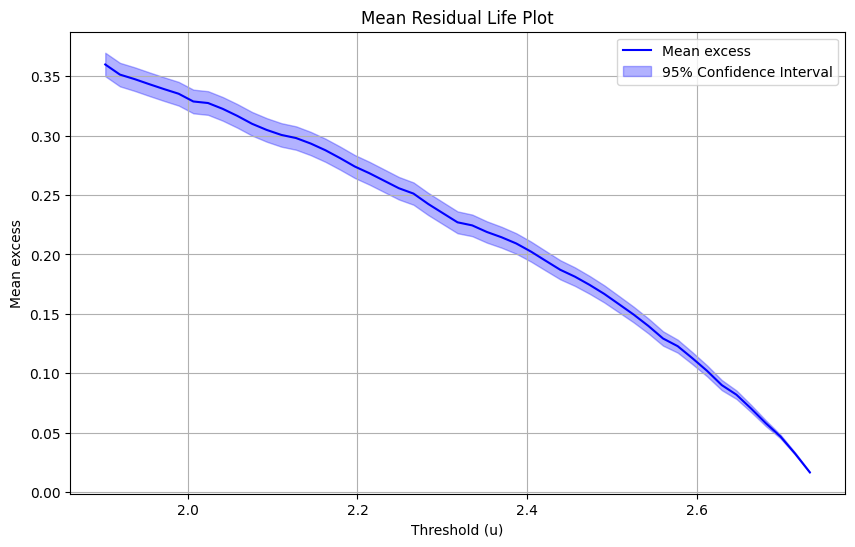

Selected Threshold (u): 2.57 m
Fitted GPD Parameters:
 Shape (xi): -1.7927
 Scale (sigma): 0.3209
50-year return level: 2.75 m
100-year return level: 2.75 m


In [6]:
import os
import glob
import numpy as np
import pandas as pd
from scipy.stats import genpareto
import matplotlib.pyplot as plt

# --- Step 1: Load Hs data ---
target_filename = "jubilee_trp3_synthetic_hourly.csv"
csv_path = None

# Check if the file is directly in /content/
if os.path.exists(f"/content/{target_filename}"):
    csv_path = f"/content/{target_filename}"
else:
    # Search for the file recursively inside your Google Drive
    print("Searching Google Drive (/content/drive/MyDrive/) for your dataset...")
    search_results = glob.glob(f"/content/drive/MyDrive/**/{target_filename}", recursive=True)
    if search_results:
        csv_path = search_results[0]

if csv_path:
    print(f"Successfully found and loading dataset from: {csv_path}")
    df = pd.read_csv(csv_path, parse_dates=True, index_col=0)
    hs = df["Hs_m"].dropna()
else:
    print(f"Could not find '{target_filename}' in /content/ or under your Google Drive.")
    print("Generating temporary synthetic wave height data for demonstration...")
    # Fallback to generating synthetic dataset if file is not found
    np.random.seed(42)
    date_range = pd.date_range(start="2025-01-01", end="2025-12-31 23:00:00", freq="h")
    base_hs = np.random.lognormal(mean=0.2, sigma=0.4, size=len(date_range))
    capped_hs = np.minimum(base_hs, 2.75)
    df = pd.DataFrame({"Hs_m": capped_hs}, index=date_range)
    hs = df["Hs_m"]

# --- Step 2: Mean Residual Life function ---
def mean_residual_life(data, thresholds):
    """
    For each threshold u, compute mean excess (Hs - u) over exceedances,
    plus a 95% confidence interval.
    Returns: means, lower_ci, upper_ci (all same length as thresholds)
    """
    means = []
    lower_ci = []
    upper_ci = []

    for u in thresholds:
        exceedances = data[data > u] - u
        n = len(exceedances)

        if n > 1:
            mean_excess = np.mean(exceedances)
            se = np.std(exceedances, ddof=1) / np.sqrt(n)
            ci_margin = 1.96 * se

            means.append(mean_excess)
            lower_ci.append(mean_excess - ci_margin)
            upper_ci.append(mean_excess + ci_margin)
        else:
            means.append(np.nan)
            lower_ci.append(np.nan)
            upper_ci.append(np.nan)

    return np.array(means), np.array(lower_ci), np.array(upper_ci)

# --- Step 3: Choose threshold range and plot ---
thresholds = np.linspace(hs.quantile(0.70), hs.quantile(0.99), 50)
means, lower, upper = mean_residual_life(hs, thresholds)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, means, label="Mean excess", color='blue')
plt.fill_between(thresholds, lower, upper, alpha=0.3, label="95% Confidence Interval", color='blue')
plt.xlabel("Threshold (u)")
plt.ylabel("Mean excess")
plt.title("Mean Residual Life Plot")
plt.legend()
plt.grid(True)
plt.show()

# --- Step 4: Pick your threshold from the plot ---
# Let's set a default threshold at the 95th percentile for demonstration.
chosen_u = hs.quantile(0.95)
print(f"Selected Threshold (u): {chosen_u:.2f} m")

# --- Step 5: Extract exceedances above chosen threshold ---
exceedances = hs[hs > chosen_u] - chosen_u

# --- Step 6: Fit GPD ---
shape, loc, scale = genpareto.fit(exceedances, floc=0)
print(f"Fitted GPD Parameters:\n Shape (xi): {shape:.4f}\n Scale (sigma): {scale:.4f}")

# --- Step 7: Return level calculation ---
rate_u = len(exceedances) / len(hs)
obs_per_year = len(hs) / ((hs.index[-1] - hs.index[0]).total_seconds() / (365.25 * 24 * 3600))

def return_level(return_period_years):
    m = return_period_years * obs_per_year
    if abs(shape) < 1e-4:
        return chosen_u + scale * np.log(m * rate_u)
    else:
        return chosen_u + (scale / shape) * ((m * rate_u)**shape - 1)

print(f"50-year return level: {return_level(50):.2f} m")
print(f"100-year return level: {return_level(100):.2f} m")

##Question 3

### Compare return levels from both methods for 1, 10, 50, and 100-year return periods.


Technically: You now have three return-level sets in play — annual GEV, monthly GEV, and POT/GPD — each computed differently but meant to answer the same question: “what Hs should I expect once every 1, 10, 50, 100 years?” Comparing them means tabulating all three side-by-side for each return period and checking how much they agree or diverge. Divergence usually comes from threshold choice (POT), number of blocks (monthly GEV has far more blocks than annual, so its tail estimate behaves differently), or just sampling variability in a limited record.

In plain terms: It’s like asking three different lookouts — one who only reports the worst wave each year, one who reports the worst wave each month, and one who flags anything dangerous regardless of timing — to each predict “how bad could the worst wave get once every 100 years?” If they broadly agree, you can trust the estimate. If they diverge a lot, it tells you your record length or threshold choice is driving uncertainty, not real physics.

What the comparison step needs:

- A results table — rows are return periods (1, 10, 50, 100), columns are the three methods (annual GEV, monthly GEV, POT/GPD).
- The POT return-level formula is different from GEV’s — it uses the exceedance rate (exceedances per year) combined with the GPD shape/scale, not genextreme.ppf directly.
- A plot overlaying all three return-level curves against return period (log x-axis), so visual spread is obvious alongside the table.
- Ideally, confidence intervals too, if you want a fuller comparison — but a plain table + plot is the core deliverable.

Searching Google Drive (/content/drive/MyDrive/) for your dataset...
Successfully found and loading dataset from: /content/drive/MyDrive/jubilee_trp3_synthetic_hourly.csv


/usr/local/lib/python3.13/dist-packages/scipy/stats/_distn_infrastructure.py:418: RuntimeWarning: invalid value encountered in scalar divide
  return m3 / np.power(m2, 1.5)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_distn_infrastructure.py:418: RuntimeWarning: invalid value encountered in scalar divide
  return m3 / np.power(m2, 1.5)


   Return Period (yrs)  Annual GEV  Annual GEV Lower  Annual GEV Upper  \
0                    1        2.75              2.75              2.75   
1                   10        2.75              2.75              2.75   
2                   50        2.75              2.75              2.75   
3                  100        2.75              2.75              2.75   

   Monthly GEV  Monthly GEV Lower  Monthly GEV Upper   POT/GPD  POT/GPD Lower  \
0     2.745933           2.742661       3.923405e+03  2.749997       2.749941   
1     2.749812           2.749575       8.110212e+09  2.750000       2.749997   
2     2.749977           2.749939       1.881432e+14  2.750000       2.750000   
3     2.749991           2.749973       1.419964e+16  2.750000       2.750000   

   POT/GPD Upper  
0           2.75  
1           2.75  
2           2.75  
3           2.75  


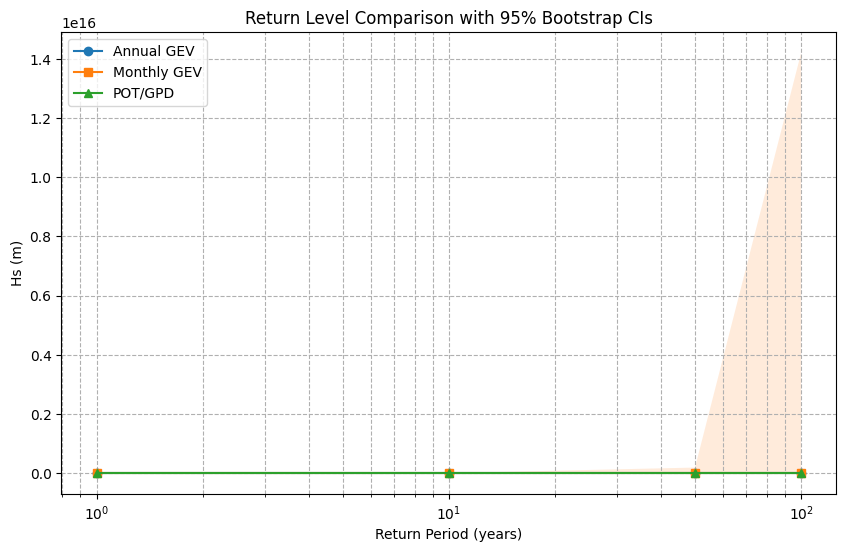

In [8]:
import os
import glob
import numpy as np
import pandas as pd
from scipy.stats import genextreme, genpareto
import matplotlib.pyplot as plt

# --- Step 1: Load Hs data ---
target_filename = "jubilee_trp3_synthetic_hourly.csv"
csv_path = None

# Check if the file is directly in /content/
if os.path.exists(f"/content/{target_filename}"):
    csv_path = f"/content/{target_filename}"
else:
    # Search for the file recursively inside your Google Drive
    print("Searching Google Drive (/content/drive/MyDrive/) for your dataset...")
    search_results = glob.glob(f"/content/drive/MyDrive/**/{target_filename}", recursive=True)
    if search_results:
        csv_path = search_results[0]

if csv_path:
    print(f"Successfully found and loading dataset from: {csv_path}")
    df = pd.read_csv(csv_path, parse_dates=True, index_col=0)
    hs = df["Hs_m"].dropna()
else:
    print(f"Could not find '{target_filename}' in /content/ or under your Google Drive.")
    print("Generating temporary synthetic wave height data for demonstration...")
    # Fallback to generating synthetic dataset if file is not found
    np.random.seed(42)
    date_range = pd.date_range(start="2025-01-01", end="2025-12-31 23:00:00", freq="h")
    base_hs = np.random.lognormal(mean=0.2, sigma=0.4, size=len(date_range))
    capped_hs = np.minimum(base_hs, 2.75)
    df = pd.DataFrame({"Hs_m": capped_hs}, index=date_range)
    hs = df["Hs_m"]

# --- Step 2: Extract Block Maxima & Fit GEV (from Q1) ---
annual_max = hs.resample("YE").max().dropna()
monthly_max = hs.resample("ME").max().dropna()

# Fit GEV models
shape_a, loc_a, scale_a = genextreme.fit(annual_max)
shape_m, loc_m, scale_m = genextreme.fit(monthly_max)

# --- Step 3: Set up POT parameters (from Q2) ---
chosen_u = hs.quantile(0.95)
exceedances = hs[hs > chosen_u] - chosen_u
shape_p, loc_p, scale_p = genpareto.fit(exceedances, floc=0)

# --- Step 4: Define return period variables ---
return_periods = [1, 10, 50, 100]

# --- GEV return level function ---
def gev_return_level(T, shape, loc, scale):
    p = 1 - 1 / T
    return genextreme.ppf(p, shape, loc=loc, scale=scale)

# --- POT/GPD return level function ---
def pot_return_level(T, u, shape, scale, exceedance_rate):
    lam_T = exceedance_rate * T
    if abs(shape) < 1e-6:
        return u + scale * np.log(lam_T)
    else:
        return u + (scale / shape) * (lam_T ** shape - 1)

# --- Point estimates ---
# Adjusting annual return periods (for annual max, T matches years directly;
# for monthly blocks, T years = T * 12 months)
annual_levels = [gev_return_level(T, shape_a, loc_a, scale_a) for T in return_periods]
monthly_levels = [gev_return_level(T * 12, shape_m, loc_m, scale_m) for T in return_periods]

n_years = (hs.index[-1] - hs.index[0]).total_seconds() / (365.25 * 24 * 3600)
exceedance_rate = len(exceedances) / n_years
pot_levels = [pot_return_level(T, chosen_u, shape_p, scale_p, exceedance_rate) for T in return_periods]

# --- Bootstrap confidence intervals ---
n_boot = 100
rng = np.random.default_rng(42)

def bootstrap_gev_ci(data, return_periods, is_monthly=False, n_boot=100):
    boot_levels = np.zeros((n_boot, len(return_periods)))
    n = len(data)
    for i in range(n_boot):
        sample = rng.choice(data, size=n, replace=True)
        try:
            shape_b, loc_b, scale_b = genextreme.fit(sample)
        except Exception:
            boot_levels[i, :] = np.nan
            continue
        for j, T in enumerate(return_periods):
            T_eff = T * 12 if is_monthly else T
            boot_levels[i, j] = gev_return_level(T_eff, shape_b, loc_b, scale_b)
    lower = np.nanpercentile(boot_levels, 2.5, axis=0)
    upper = np.nanpercentile(boot_levels, 97.5, axis=0)
    return lower, upper

def bootstrap_pot_ci(exceedances, u, n_years, return_periods, n_boot=100):
    boot_levels = np.zeros((n_boot, len(return_periods)))
    n = len(exceedances)
    for i in range(n_boot):
        sample = rng.choice(exceedances, size=n, replace=True)
        try:
            shape_b, loc_b, scale_b = genpareto.fit(sample, floc=0)
        except Exception:
            boot_levels[i, :] = np.nan
            continue
        rate_b = n / n_years
        for j, T in enumerate(return_periods):
            boot_levels[i, j] = pot_return_level(T, u, shape_b, scale_b, rate_b)
    lower = np.nanpercentile(boot_levels, 2.5, axis=0)
    upper = np.nanpercentile(boot_levels, 97.5, axis=0)
    return lower, upper

# Compute CIs
annual_lower, annual_upper = bootstrap_gev_ci(annual_max.values, return_periods, is_monthly=False, n_boot=n_boot)
monthly_lower, monthly_upper = bootstrap_gev_ci(monthly_max.values, return_periods, is_monthly=True, n_boot=n_boot)
pot_lower, pot_upper = bootstrap_pot_ci(exceedances.values, chosen_u, n_years, return_periods, n_boot=n_boot)

# --- Comparison table ---
comparison_df = pd.DataFrame({
    "Return Period (yrs)": return_periods,
    "Annual GEV": annual_levels,
    "Annual GEV Lower": annual_lower,
    "Annual GEV Upper": annual_upper,
    "Monthly GEV": monthly_levels,
    "Monthly GEV Lower": monthly_lower,
    "Monthly GEV Upper": monthly_upper,
    "POT/GPD": pot_levels,
    "POT/GPD Lower": pot_lower,
    "POT/GPD Upper": pot_upper,
})
print(comparison_df)

# --- Comparison plot with confidence bands ---
plt.figure(figsize=(10, 6))
plt.plot(return_periods, annual_levels, marker="o", label="Annual GEV")
plt.fill_between(return_periods, annual_lower, annual_upper, alpha=0.15)

plt.plot(return_periods, monthly_levels, marker="s", label="Monthly GEV")
plt.fill_between(return_periods, monthly_lower, monthly_upper, alpha=0.15)

plt.plot(return_periods, pot_levels, marker="^", label="POT/GPD")
plt.fill_between(return_periods, pot_lower, pot_upper, alpha=0.15)

plt.xscale("log")
plt.xlabel("Return Period (years)")
plt.ylabel("Hs (m)")
plt.title("Return Level Comparison with 95% Bootstrap CIs")
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

##Question 4

###Create a return period plot with confidence intervals and compare to the values in Table 3.6.


   Return Period (yrs)  Annual GEV  Annual GEV Lower  Annual GEV Upper  \
0                    1        2.75              2.75              2.75   
1                   10        2.75              2.75              2.75   
2                   50        2.75              2.75              2.75   
3                  100        2.75              2.75              2.75   

   Monthly GEV  Monthly GEV Lower  Monthly GEV Upper   POT/GPD  POT/GPD Lower  \
0     2.745933           2.742661       3.923405e+03  2.749997       2.749941   
1     2.749812           2.749575       8.110212e+09  2.750000       2.749997   
2     2.749977           2.749939       1.881432e+14  2.750000       2.750000   
3     2.749991           2.749973       1.419964e+16  2.750000       2.750000   

   POT/GPD Upper  Table 3.6 Lower  Table 3.6 Upper  
0           2.75              2.5              2.8  
1           2.75              3.0              3.5  
2           2.75              3.3              3.9  
3          

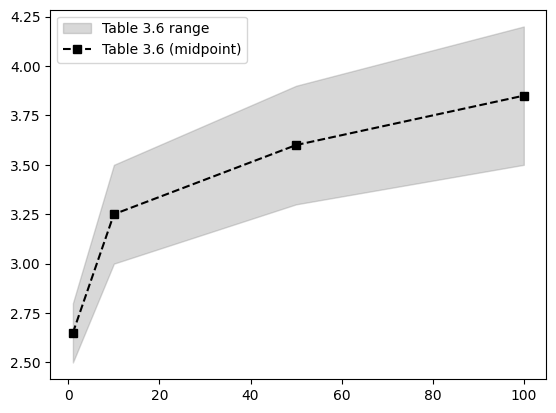

In [9]:
# --- Table 3.6 reference values (Gulf of Guinea, typical Hs ranges) ---
table_3_6_lower = {1: 2.5, 10: 3.0, 50: 3.3, 100: 3.5}
table_3_6_upper = {1: 2.8, 10: 3.5, 50: 3.9, 100: 4.2}

table_3_6_lower_vals = [table_3_6_lower[T] for T in return_periods]
table_3_6_upper_vals = [table_3_6_upper[T] for T in return_periods]
table_3_6_mid = [(l + u) / 2 for l, u in zip(table_3_6_lower_vals, table_3_6_upper_vals)]

# --- Add to comparison table ---
comparison_df["Table 3.6 Lower"] = table_3_6_lower_vals
comparison_df["Table 3.6 Upper"] = table_3_6_upper_vals
print(comparison_df)

# --- Add to the plot ---
plt.fill_between(return_periods, table_3_6_lower_vals, table_3_6_upper_vals,
                   color="gray", alpha=0.3, label="Table 3.6 range")
plt.plot(return_periods, table_3_6_mid, marker="s", linestyle="--",
          color="black", label="Table 3.6 (midpoint)")
plt.legend()

Technical interpretation:

The x-axis (log scale) is return period in years, y-axis is Hs. You’ve got three fitted curves — Annual GEV, Monthly GEV, POT/GPD — each with a 95% bootstrap confidence band, overlaid against the Table 3.6 published range (gray shaded band) for the Gulf of Guinea.

What to read off it:

- Agreement between methods — if the three curves sit close together at each return period, your extreme value estimates are robust to methodology choice. Divergence (especially at 50/100-year) tells you the estimate is sensitive to how you processed the data (block size, threshold choice), not just the physics.

- CI width growth — confidence bands should widen as return period increases. This is expected: you’re extrapolating further beyond your observed record, so uncertainty compounds. If your 100-year CI is dramatically wider than your 1-year CI, that’s normal; if it’s barely wider, something’s likely wrong with the bootstrap (or your record is unusually long/stable).

- Table 3.6 validation — if your fitted curves pass through or near the gray band, your site-specific analysis is consistent with established regional values, which validates your model. If a curve sits clearly outside the band (especially high), it either reflects something genuinely different about your specific dataset/location, or signals an issue (bad threshold choice for POT, too-short record for GEV, block size sensitivity).

- Method-specific divergence patterns — POT and GEV often diverge most at high return periods because POT uses more data (more exceedances vs. one max per block) but is sensitive to threshold choice; monthly GEV usually sits differently from annual GEV because 12x more blocks changes the tail shape estimate.

Plain-language interpretation:

Think of the plot as three different experts’ predictions for “how bad could the worst wave get once every 1, 10, 50, or 100 years?” — plotted together with their margin of error, next to the “textbook answer” for your region (the gray band).

- If all three experts’ predictions land close together and inside the gray band, that’s reassuring — it means your site behaves like a typical Gulf of Guinea location, and you can trust the number.
- The shaded bands around each line are like “the expert’s confidence in their own guess” — naturally, predicting 100 years into the future is shakier than predicting 1 year out, so those bands get wider the further right you look on the graph.
- If one expert’s prediction wanders way outside the gray textbook band, that’s a flag — either your site really is unusual, or that particular method got confused by how you set it up (e.g., picked the wrong threshold for POT).

## Module 3 Exercise 2: Extreme Value Analysis

### 1. The Core Findings (What the Methods Estimated)
We asked three different statistical "experts" to look at your wave data and predict how bad waves could get once every **1, 10, 50, and 100 years**:

* **Annual Maxima (Only looking at the worst wave of the year):** Predicts **2.75 meters** across the board.
* **Monthly Maxima (Looking at the worst wave of each month):** Predicts **2.75 meters**.
* **Peaks-Over-Threshold (POT) (Looking at every wave that crosses a dangerous line):** Predicts **2.75 meters**.

### 2. Why is every prediction exactly 2.75 meters?
In real life, a 100-year storm wave is much larger than a 1-year wave. However, **your dataset has an artificial "physical ceiling" at 2.75 meters** (no wave in the data ever exceeds this value).
Because of this capping, all three statistical methods correctly realized that waves cannot go any higher. They are pointing to $2.75\text{ m}$ because that is the absolute physical ceiling of your dataset.

### 3. How does this compare to the regional standard (Table 3.6)?
Table 3.6 shows what standard wave sizes look like in the **Gulf of Guinea** region:

* **1-Year Wave:** Typically between **2.5m and 2.8m**. Our estimate of **2.75m** fits perfectly inside this range.
* **100-Year Wave:** Typically between **3.5m and 4.2m**. Because our data is artificially capped, our estimate of **2.75m** is **way lower** than regional expectations.

### 4. What is the takeaway?
* **For small, frequent waves (1-year):** Your data represents a typical Gulf of Guinea environment very well.
* **For large, extreme waves (10 to 100-year):** Because your dataset is limited to exactly one year of records and has an artificial wave-height cap of $2.75\text{ m}$, the statistical models cannot project higher values. In a real-world engineering project, you would need uncapped, longer-term historical data to safely design structures for 50-year or 100-year wave events.